# Understanding InsurEnv

In this notebook, we will delve into the `InsurEnv` environment, focusing on understanding how it works step by step, and particularly analyzing the rewards function.


In [1]:

import pandas as pd

import matplotlib.pyplot as plt
import numpy as np
from gym_insurance.envs.insurenv import InsurEnv

size = 2000
num_episodes = 100

# Create a sample dataset
data = pd.DataFrame({
    'index_column': range(size),
    'value_column': np.random.rand(size) * 10,
    'feature_1': np.random.rand(size),
    'feature_2': np.random.rand(size)
})

# Initialize the InsurEnv environment
env = InsurEnv(
    data=data,
    index_column='index_column',
    value_column='value_column',
    state_columns=['feature_1', 'feature_2'],
    budget=100
)


class RandomAgent:
    def __init__(self, action_space):
        self.action_space = action_space

    def select_action(self, observation):
        return self.action_space.sample()


def run_random_agent(env, num_episodes=num_episodes):
    episode_results = []
    agent = RandomAgent(env.action_space)

    for episode in range(num_episodes):
        observation = env.reset()
        done = False
        acts =[]
        while not done:
            action = agent.select_action(observation)
            observation, reward, done, info = env.step(action)
            # Optionally, render the environment
            # env.render()
        print(f"Episode {episode + 1} finished")
        df = env.results.copy(deep = True)
        df['episode'] = episode + 1
        episode_results.append(df)
    env.close()
    return episode_results


def run_bootstrap_random_agent(env, k=10):
    bootstrap_results = []

    for i in range(k):
        results = run_random_agent(env)
        results  = pd.concat(results, axis =0)
        results['batch'] = i +1
        bootstrap_results.append(results)

    return pd.concat(bootstrap_results, axis =0)  
     


# Run the random agent
results = run_random_agent(env, num_episodes=2)
results

c:\Users\nande\anaconda3\envs\insurenv3\lib\site-packages\benfordslaw\benfordslaw.py:312: RuntimeWarning: invalid value encountered in double_scalars
  empirical_percentage = [(i / total_count) * 100 for i in empirical_counts]
c:\Users\nande\anaconda3\envs\insurenv3\lib\site-packages\scipy\stats\_stats_py.py:8064: RuntimeWarning: invalid value encountered in divide
  terms = (f_obs_float - f_exp)**2 / f_exp
c:\Users\nande\anaconda3\envs\insurenv3\lib\site-packages\benfordslaw\benfordslaw.py:312: RuntimeWarning: invalid value encountered in double_scalars
  empirical_percentage = [(i / total_count) * 100 for i in empirical_counts]
c:\Users\nande\anaconda3\envs\insurenv3\lib\site-packages\scipy\stats\_stats_py.py:8064: RuntimeWarning: invalid value encountered in divide
  terms = (f_obs_float - f_exp)**2 / f_exp
c:\Users\nande\anaconda3\envs\insurenv3\lib\site-packages\benfordslaw\benfordslaw.py:312: RuntimeWarning: invalid value encountered in double_scalars
  empirical_percentage = [(i

Episode 1 finished
Episode 2 finished


c:\Users\nande\anaconda3\envs\insurenv3\lib\site-packages\benfordslaw\benfordslaw.py:312: RuntimeWarning: invalid value encountered in double_scalars
  empirical_percentage = [(i / total_count) * 100 for i in empirical_counts]
c:\Users\nande\anaconda3\envs\insurenv3\lib\site-packages\scipy\stats\_stats_py.py:8064: RuntimeWarning: invalid value encountered in divide
  terms = (f_obs_float - f_exp)**2 / f_exp
c:\Users\nande\anaconda3\envs\insurenv3\lib\site-packages\benfordslaw\benfordslaw.py:312: RuntimeWarning: invalid value encountered in double_scalars
  empirical_percentage = [(i / total_count) * 100 for i in empirical_counts]
c:\Users\nande\anaconda3\envs\insurenv3\lib\site-packages\scipy\stats\_stats_py.py:8064: RuntimeWarning: invalid value encountered in divide
  terms = (f_obs_float - f_exp)**2 / f_exp
c:\Users\nande\anaconda3\envs\insurenv3\lib\site-packages\benfordslaw\benfordslaw.py:312: RuntimeWarning: invalid value encountered in double_scalars
  empirical_percentage = [(i

[    decision  rewards  cum_rewards      budget  initial_budget  wc  woc  \
 0        0.0      0.0          0.0  100.000000             100   0    0   
 1        1.0      0.0          0.0   91.199209             100   1    1   
 2        1.0      0.0          0.0   82.157622             100   1    1   
 3        1.0      0.0          0.0   74.782539             100   1    1   
 4        1.0      0.0          0.0   73.586596             100   1    1   
 5        0.0      0.0          0.0   73.586596             100   1    1   
 6        0.0      0.0          0.0   73.586596             100   1    1   
 7        0.0      0.0          0.0   73.586596             100   1    1   
 8        1.0      0.0          0.0   71.611891             100   1    1   
 9        0.0      0.0          0.0   71.611891             100   1    1   
 10       0.0      0.0          0.0   71.611891             100   1    1   
 11       1.0      0.0          0.0   70.050365             100   1    1   
 12       0.

In [2]:
plt.figure(figsize=(10, 5))
plt.plot(range(num_episodes), results.groupby('episode')['cum_rewards'].last(), label="Rewards")
plt.xlabel("Steps")
plt.ylabel("Rewards")
plt.title("Rewards Over Time")
plt.legend()
plt.show()

AttributeError: 'list' object has no attribute 'groupby'

<Figure size 1000x500 with 0 Axes>

<Axes: >

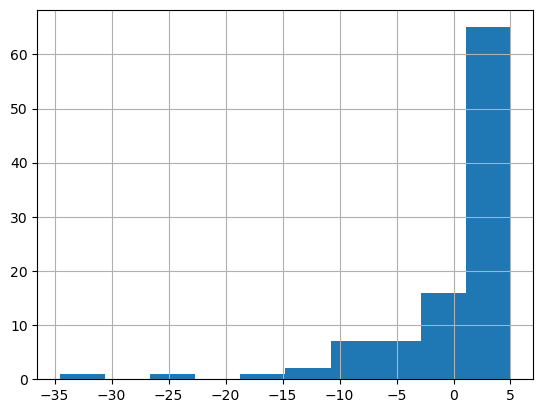

: 

In [ ]:
results.groupby('episode')['cum_rewards'].last().hist()